# Fundamentos del procesado de imagen
Mikel De Iturrate basado en el tutorial de Rodrigo. Mondragon Unibersitatea. Health Data Analytics. 2026-2027.

En este notebook aprenderemos lo básico sobre procesado de imagen usando [Scikit-Image](https://scikit-image.org/). Esta librería aparece con el nombre _skimage_ en Python (abreviado como ski). Contiene una buena colleción de algoritmos para el procesado de imagen en Python. Si os interesa podéis utilizar recursos adicionales disponibles en la página web de la librería.


In [1]:
# Importar las librerías necesarias
import skimage as ski
import matplotlib.pyplot as plt
import numpy as np

## Enseñar una imagen

Para enseñar una imagen usaremos la librería matplotlib.pyplot (plt).

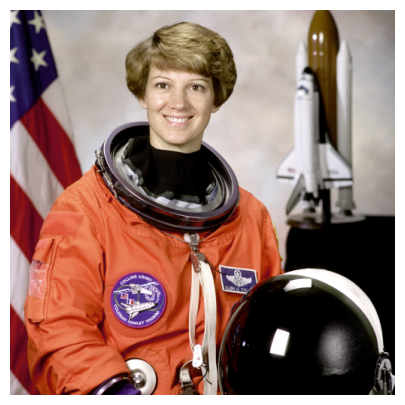

In [2]:
# Cargar la imagen de ejemplo de skimage
image = ski.data.astronaut()

# Podemos determinar el tamaño del lienzo de matplotlib usando figsize
plt.figure(figsize=(5,5))
# Comúnmente en las imágenes desactivamos el eje para una mejor visualización
plt.axis('off')
plt.imshow(image)
plt.show()


## Explorando la imagen

Por defecto, la imagen que hemos cargado es un array n-dimensional de numpy. Puedes mirar en detalle que es un array de numpy [aquí](https://numpy.org/doc/2.3/reference/generated/numpy.ndarray.html). Estas son las características más comunes que solemos extraer de una imagen durante una exploración inicial:
* El tipo de dato de la matriz de imagen
* El tamaño de la imagen
* El tipo de dato de cada pixel
* El rango de valores de la imagen


In [3]:
# Explorar el tipo de datos y la forma de la imagen
# Obtener el tipo de la imagen
print("El tipo de la imagen es: ", type(image))
# Obtener el tamaño de la imagen
print("El tamaño de la imagen es: ", image.shape)
# Obtener el tipo de datos de un solo píxel
print("El tipo de dato de un solo píxel es: ", image.dtype)
# Obtener el rango de valores de la imagen
print("El rango de valores de la imagen es: ", image.min(), " a ", image.max())

El tipo de la imagen es:  <class 'numpy.ndarray'>
El tamaño de la imagen es:  (512, 512, 3)
El tipo de dato de un solo píxel es:  uint8
El rango de valores de la imagen es:  0  a  255


## Cálculo de la intensidad de la imagen
Usando el tamaño de la imagen como prueba podemos determinar que tenemos una imagen RGB. Esto quiere decir que tiene 3 dimensiones y que esta tercera dimensión corresponde a los canales de color de la imagen. Uno de los primeros pasos que hacemos durante el procesado de la imagen es pasar la imagen a escala de grises, es decir calcular la escala de intensidad de nuestra imagen. Para ello, podemos usar la función [rgb2gray](https://scikit-image.org/docs/0.25.x/auto_examples/color_exposure/plot_rgb_to_gray.html) en scikit-learn. También es posible calcular la imagen manualmente usando una suma ponderada de los diferentes canales de color:

$$ Gray = 0.2125 R + 0.7154 G + 0.0721 B$$


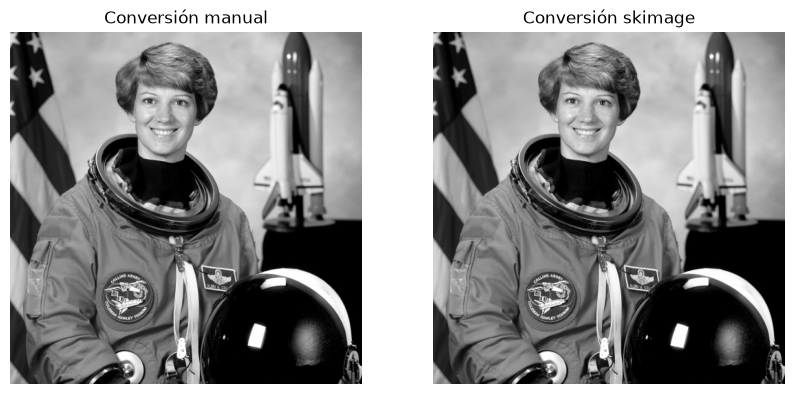

In [4]:
gray_image_ski = ski.color.rgb2gray(image)
# Ahora vamos a convertir la imagen a escala de grises manualmente usando la fórmula de luminancia
gray_image_manual = 0.2125 * image[:,:,0] + 0.7154 * image[:,:,1] + 0.0721 * image[:,:,2]
# Podemos verificar que ambas imágenes son iguales
fig, axs = plt.subplots(1,2, figsize=(10,5))
axs[0].set_title('Conversión manual')
axs[0].axis('off')
axs[0].imshow(gray_image_manual, cmap='gray')
axs[1].set_title('Conversión skimage')
axs[1].axis('off')
axs[1].imshow(gray_image_ski, cmap='gray')
plt.show()

Ahora podemos comprobar que la imagen en escala de grises ha perdido la dimensión de los canales de color.

In [5]:
print("La imagen en escala de grises tiene un solo canal: ", gray_image_ski.ndim == 2)
# Enseñar el tamaño de la imagen en escala de grises
print("El tamaño de la imagen en escala de grises es: ", gray_image_ski.shape)

La imagen en escala de grises tiene un solo canal:  True
El tamaño de la imagen en escala de grises es:  (512, 512)


## Cambiar el tamaño de una imagen

Una de las transformaciones más comunes en imagenes es el cambio de tamaño o _resizing_. Cuando cambiamos el tamaño, hacemos un cambio en el espacio donde está contenida la imagen, pero no alteramos directamente los valores de los pixeles. Al cambiar el tamaño podemos hacer dos cosas:
* **Upscaling**: Incrementar el tamaño de la imagen. Se usa para observar detalles pequeños de la imagen original.
* **Downscaling**: Reducir el tamaño de la imagen. Proceso común en entrenamiento de redes neuronales para procesar más imagenes a la vez de una forma más eficiente.

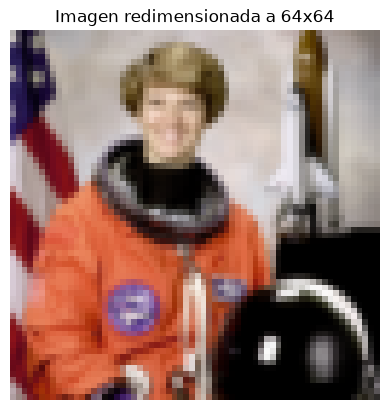

In [6]:
# Utilizamos la función resize de skimage para redimensionar la imagen a 64x64 píxeles
resized_image = ski.transform.resize(image,(64, 64))
plt.imshow(resized_image)
plt.title('Imagen redimensionada a 64x64')
plt.axis('off')
plt.show()

Como puedes ver en la imagen superior, no hay un cambio directo de los valores de intensidad de los píxeles, sino es el propio cambio en el espacio de la imagen lo que genera estos cambios. En estos casos, utilizamos la interpolación para determinar el nuevo valor de mi pixel. Hay varios métodos de interpolación dependiendo del orden de mi función de aproximación:

* **Primer orden**: Nearest neighbour
* **Segundo orden**: Bilinear 
* **Tercer orden**: Bicubic
* **Cuarto orden**: Lanczos

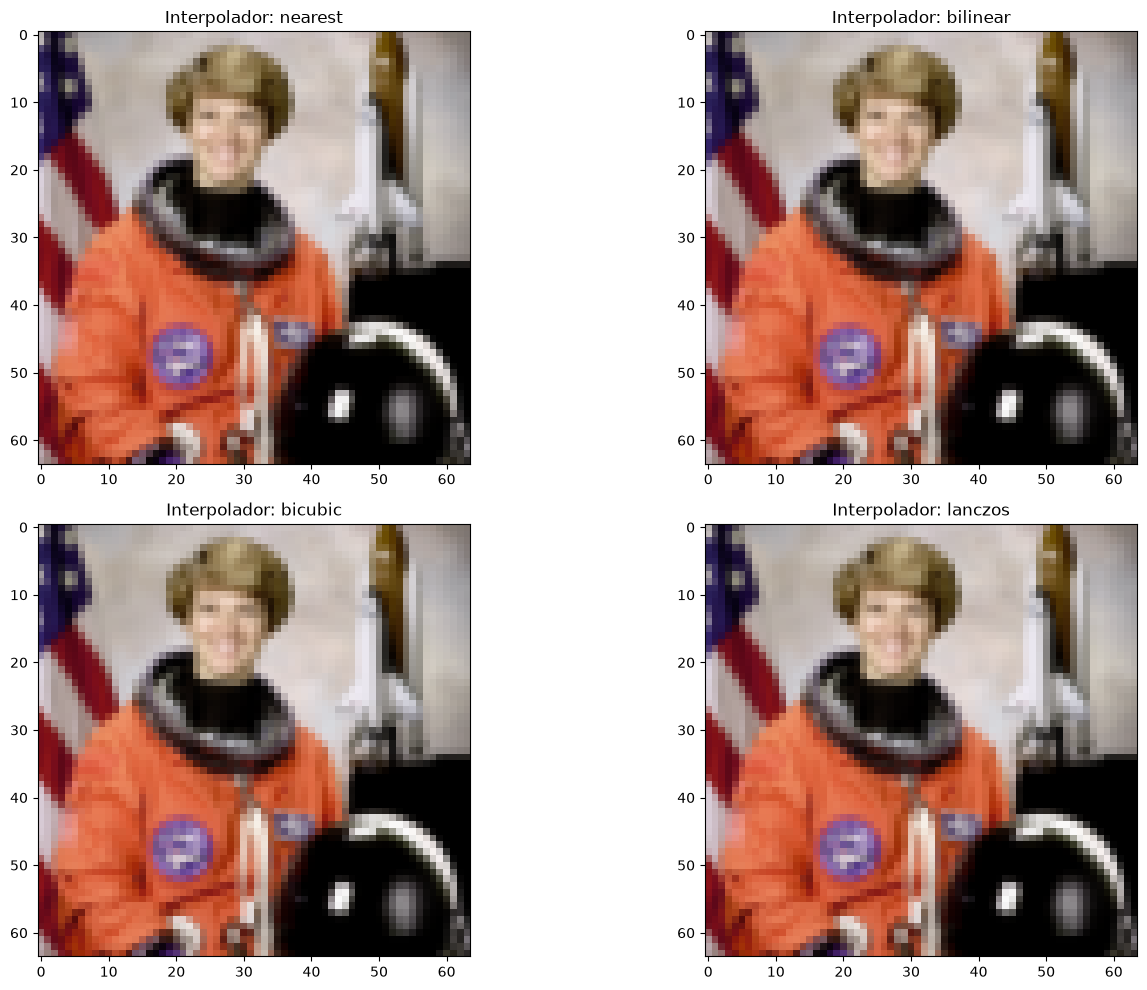

In [7]:
# Utilizamos la función resize de skimage para redimensionar la imagen a 64x64 píxeles con diferentes interpoladores
plt.figure(figsize=(15, 10))

# Los interpoladores disponibles en skimage son: 'nearest', 'bilinear', 'bicubic', 'lanczos'
interpolators = ['nearest', 'bilinear', 'bicubic', 'lanczos']

# Aplicamos los interpoladores a la imagen y mostramos los resultados de forma iterativa
for i, interpolator in enumerate(interpolators):
  resized_image = ski.transform.resize(image, (64, 64), order=i, anti_aliasing=True)
  plt.subplot(2, 2, i + 1)
  plt.imshow(resized_image)
  plt.title(f"Interpolador: {interpolator}")

plt.tight_layout()
plt.show()


## Transformaciones de profundidad de bit

Las transformaciones de bit-depth se refiere al proceso de cambiar el rango de valores que puede tener un pixel. Este tipo de cambios altera los detalles de la imagen y puede reducir o incrementar el rango de valores que se pueden expresar en cada pixel. Una reducción en la profundidad puede significar una reducción de la cantidad de memoria que ocupa mi imagen. Por otro lado, un incremento puede significar mayor precisión en cálculos aritméticos con las imagenes. En este caso, pongo una cuantificación de 2- y 4-bit para la imagen.

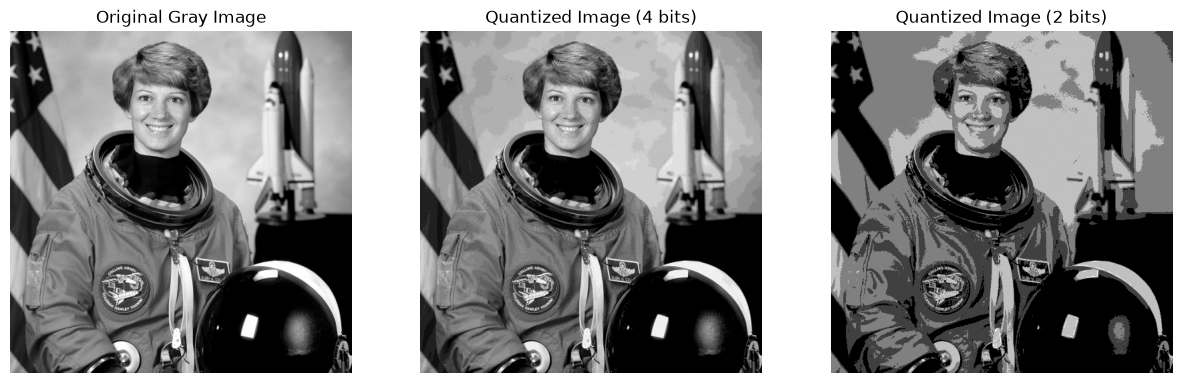

In [8]:
import numpy as np

# Quantización de la imagen en escala de grises a 2 bits y 4 bits
quantized_image_2bit = np.floor(gray_image_ski * 4) / 4
quantized_image_4bit = np.floor(gray_image_ski * 16) / 16

# Mostrar las imágenes original y cuantizadas
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].axis('off')
axs[0].imshow(gray_image_ski, cmap='gray')
axs[0].set_title('Original Gray Image')
axs[1].axis('off')
axs[1].imshow(quantized_image_4bit, cmap='gray')
axs[1].set_title('Quantized Image (4 bits)')
axs[2].axis('off')
axs[2].imshow(quantized_image_2bit, cmap='gray')
axs[2].set_title('Quantized Image (2 bits)')
plt.show()


## Ruido en la imagen

El ruido es una variación aleatoria de la señal original de la imagen. Puede ser consecuencia de varios factores como iluminación pobre, sobre exposición lumínica, problemas en el circuito electrónico de los sensores, etc. Podemos representar el ruido como una función $n(x)$ que afecta independientemente cada pixel y tiene el mismo tamaño que nuestra imagen.

$$ I(x) = O(x) + n(x)$$

Dependiendo de como es el ruido podemos diferenciar diferentes tipos y cada uno de ellos se reduce usando una metodología diferente:
* Ruido Gaussiano
* Ruido uniforme
* Ruido _Salt & Pepper_

En este ejemplo, se demuestra como podemos generar ruido Gaussiano artificial y añadirlo a nuestra imagen. Tras ello, usamos un filtro mediano (calculamos la media de varias imágenes con ruido) para reducir su efecto.

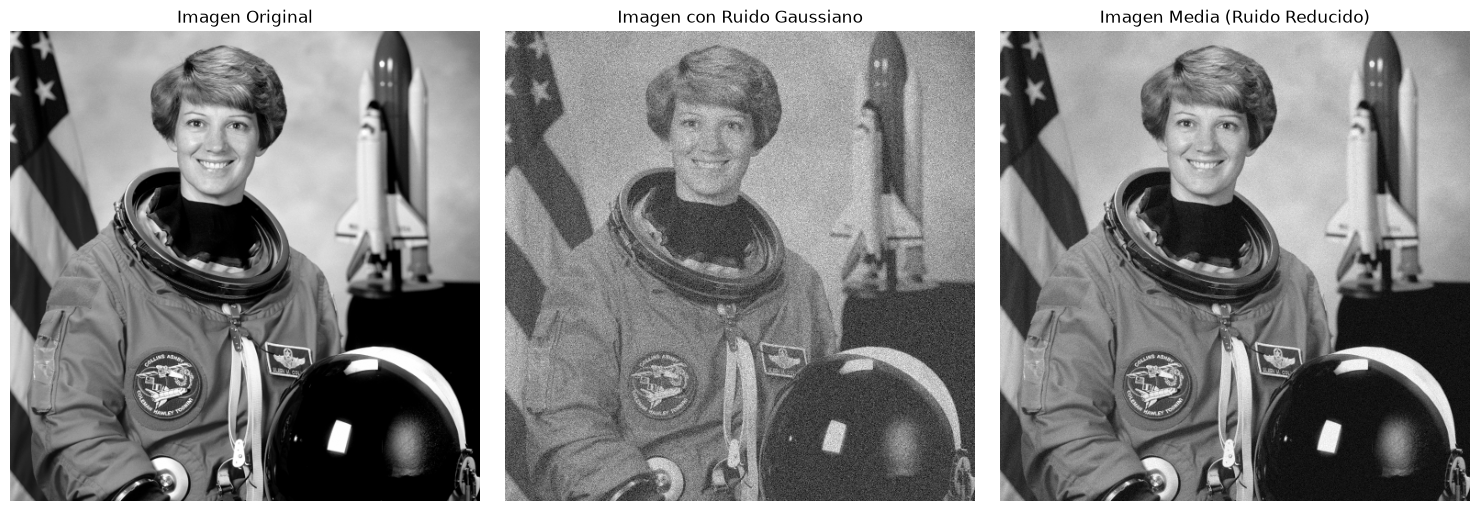

In [9]:
import skimage as ski
import matplotlib.pyplot as plt
import numpy as np

# Asumimos que la imagen en escala de grises ya ha sido cargada y está disponible como gray_image_ski

plt.figure(figsize=(15, 5))

# Imagen original
plt.subplot(1, 3, 1)
plt.imshow(gray_image_ski, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

# Agregar ruido gaussiano y calcular la imagen media
noisy_images = []
for _ in range(30):
  noise = np.random.normal(loc=0, scale=0.1, size=gray_image_ski.shape)
  noisy_image = gray_image_ski + noise
  noisy_images.append(noisy_image)

# Primera imagen con ruido gaussiano
plt.subplot(1, 3, 2)
plt.imshow(noisy_images[0], cmap='gray')
plt.title('Imagen con Ruido Gaussiano')
plt.axis('off')

# Imagen media
mean_image = np.mean(noisy_images, axis=0)
plt.subplot(1, 3, 3)
plt.imshow(mean_image, cmap='gray')
plt.title('Imagen Media (Ruido Reducido)')
plt.axis('off')

plt.tight_layout()
plt.show()


Podemos intentar determinar un mapa del ruido sustrayendo la imagen ruidosa de la imagen original y de nuestra reconstrucción. Con este proceso también es posible calcular la precisión de nuestro proceso de reconstrucción de la imagen original utilizando la imagen ruidosa.

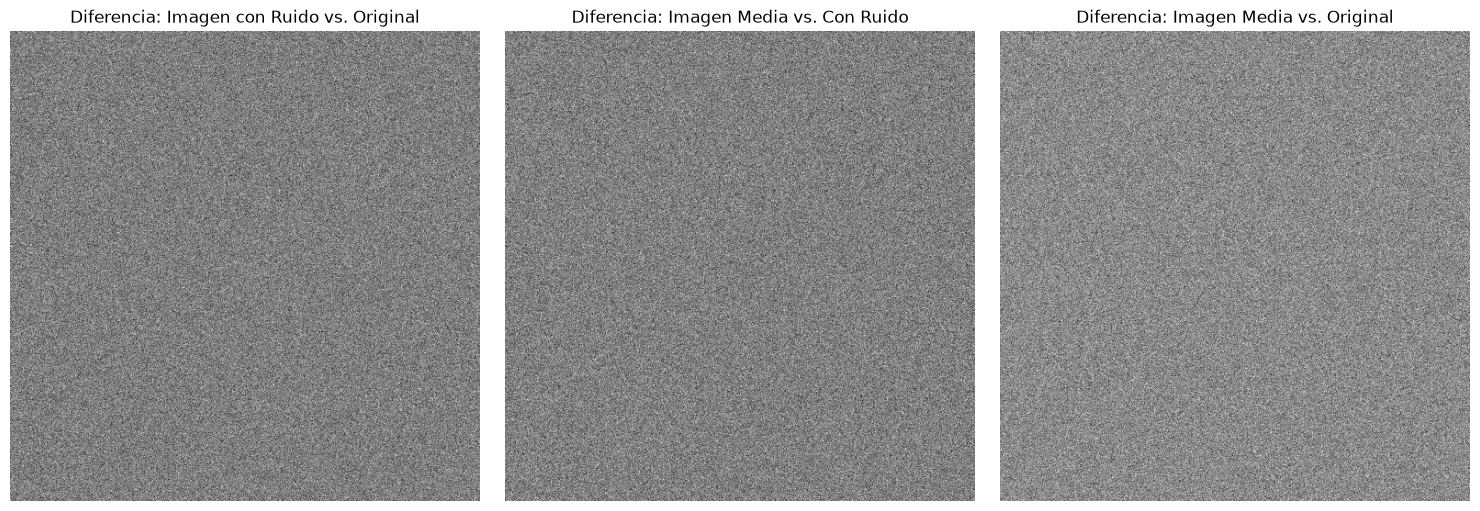

In [10]:
plt.figure(figsize=(15, 5))

# Diferencia entre la imagen con ruido y la imagen original
difference_noisy_original = noisy_images[0] - gray_image_ski
plt.subplot(1, 3, 1)
plt.imshow(difference_noisy_original, cmap='gray')
plt.title('Diferencia: Imagen con Ruido vs. Original')
plt.axis('off')


# Diferencia entre la imagen media y la imagen con ruido
difference_mean_noisy = mean_image - noisy_images[0]
plt.subplot(1, 3, 2)
plt.imshow(difference_mean_noisy, cmap='gray')
plt.title('Diferencia: Imagen Media vs. Con Ruido')
plt.axis('off')

# Diferencia entre la imagen media y la imagen original
difference_mean_original = mean_image - gray_image_ski
plt.subplot(1, 3, 3)
plt.imshow(difference_mean_original, cmap='gray')
plt.title('Diferencia: Imagen Media vs. Original')
plt.axis('off')


plt.tight_layout()
plt.show()


## Multiplicaciones y divisiones con imágenes

El uso de multiplicaciones y divisiones con imágenes no es tan normal dentro del procesado de imágenes. Aún así, una de las aplicaciones más comunes de estas operaciones es para conseguir una iluminación uniforme en las imágenes que tienen un gradiente de luz. En el ejemplo de abajo, se demuestra como crear un gradiente, aplicarlo a la imagen original y luego reducir su efecto usando multiplicaciones y divisiones.

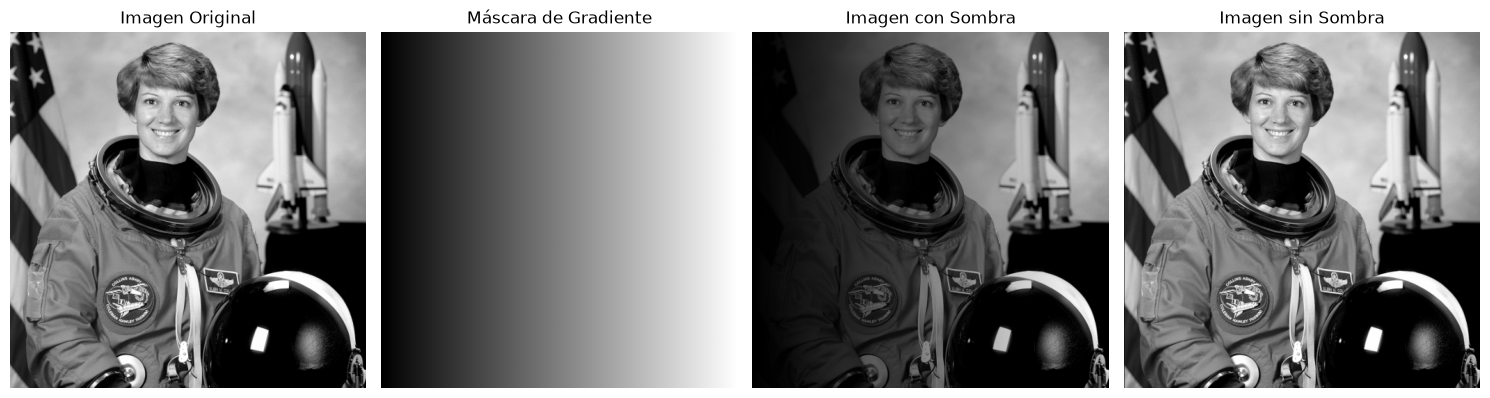

In [11]:
# Generar una máscara de gradiente que simule una sombra en la imagen
mask = np.linspace(0, 1, gray_image_ski.shape[1]).reshape(1, -1)
mask = np.repeat(mask, gray_image_ski.shape[0], axis=0)

# Multiplicar la imagen por la máscara para simular una sombra
shadowed_image = gray_image_ski * mask

# Divide la imagen con sombra por la máscara para eliminar la sombra
deshadowed_image = shadowed_image / (mask + 1e-6)  # Agregar una constante pequeña para evitar la división por cero que puede ocurrir en los bordes de la imagen

plt.figure(figsize=(15, 5))

# Imagen original
plt.subplot(1, 4, 1)
plt.imshow(gray_image_ski, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

# Máscara de gradiente
plt.subplot(1, 4, 2)
plt.imshow(mask, cmap='gray')
plt.title('Máscara de Gradiente')
plt.axis('off')

# Imagen con sombra
plt.subplot(1, 4, 3)
plt.imshow(shadowed_image, cmap='gray')
plt.title('Imagen con Sombra')
plt.axis('off')

# Imagen sin sombra
plt.subplot(1, 4, 4)
plt.imshow(deshadowed_image, cmap='gray')
plt.title('Imagen sin Sombra')
plt.axis('off')

plt.tight_layout()
plt.show()


## Operaciones binarias

Las operaciones binarias entre una imagen y una máscara se pueden entender también como una multiplicación entre dos imágenes. El objetivo principal de este proceso es resaltar una Región de Interes (ROI) en la imagen de la que queremos extraer información adicional. Con esta operación transformamos en 0 cualquier valor fuera de nuestra región de interes y mantenemos los valores originales de la imagen dentro de la región.

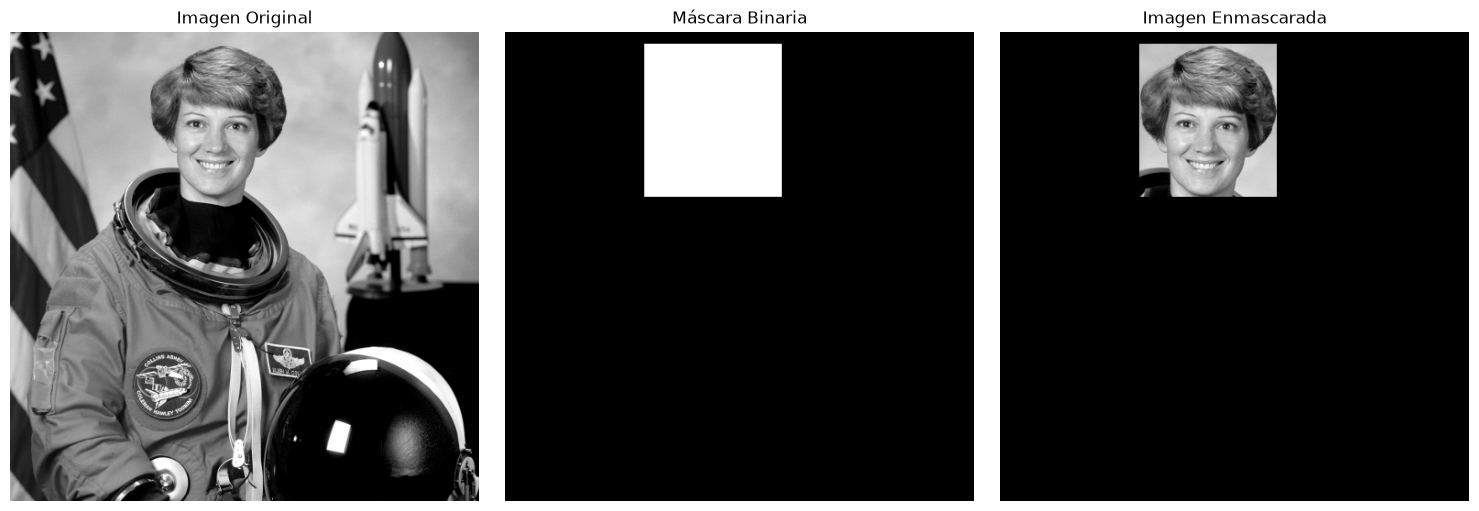

In [12]:
# Crear una máscara binaria para la región de interés (por ejemplo, la cara del astronauta)
mask = np.zeros_like(gray_image_ski)
mask[13:180, 152:302] = 1  # Coordenadas de ejemplo para la región de la cara, se pueden ajustar según sea necesario

# Aplicar la máscara a la imagen original
masked_image = gray_image_ski * mask

plt.figure(figsize=(15, 5))

# Imagen original
plt.subplot(1, 3, 1)
plt.imshow(gray_image_ski, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

# Máscara binaria
plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title('Máscara Binaria')
plt.axis('off')

# Imagen enmascarada
plt.subplot(1, 3, 3)
plt.imshow(masked_image, cmap='gray')
plt.title('Imagen Enmascarada')
plt.axis('off')

plt.tight_layout()
plt.show()


## Transformaciones geométricas

Al igual que el cambio de tamaño, las transformaciones geométricas alterar la posición y la composición espacial de nuestros píxeles. Para determinar su nuevo valor utilizamos interpolación. Las transformaciones geométricas más comunes utilizan las matriz de transformaciones afines. La identidad $I$ se utiliza para representar la imagen original y para el resto de transformaciones utilizamos diferentes puntos para su transformación.

* Identidad
$$I = \begin{bmatrix}
1 & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & 1
\end{bmatrix}$$

* Escalado
  $$S = \begin{bmatrix}
    s_x & 0 & 0 \\
    0 & s_y & 0 \\
    0 & 0 & 1
    \end{bmatrix}$$

* Rotación
  $$R = \begin{bmatrix}
    \cos(\theta) & -\sin(\theta) & 0 \\
    \sin(\theta) & \cos(\theta) & 0 \\
    0 & 0 & 1
    \end{bmatrix}$$
* Translación
  $$T = \begin{bmatrix}
    1 & 0 & t_x \\
    0 & 1 & t_y \\
    0 & 0 & 1
    \end{bmatrix}$$
* Cizallamiento
  $$Sh = \begin{bmatrix}
    1 & sh_x & 0 \\
    sh_y & 1 & 0 \\
    0 & 0 & 1
    \end{bmatrix}$$

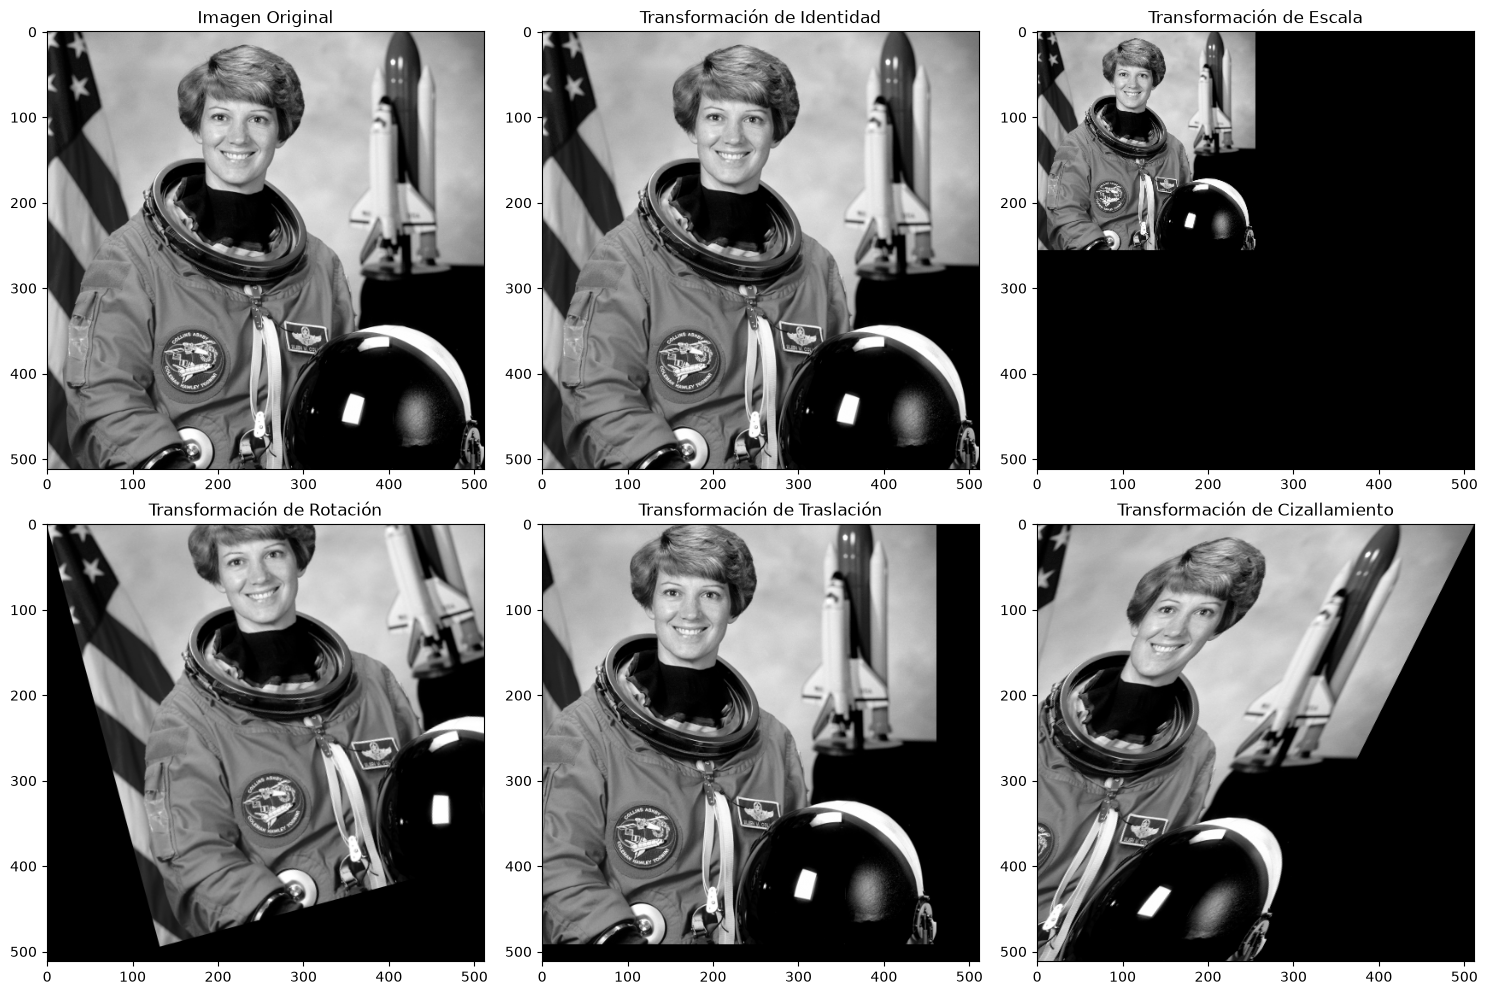

In [13]:
import skimage.transform as transform

# Transformaciones afines: identidad, escala, rotación, traslación y cizallamiento

# Transformación de identidad (no cambia la imagen)
identity_matrix = np.array([[1, 0, 0],
                           [0, 1, 0],
                           [0, 0, 1]])
identity_transformed_image = transform.warp(gray_image_ski, transform.AffineTransform(matrix=identity_matrix))

# Transformación de escala (por ejemplo, duplicar el tamaño)
scale = 2 # Ajustable según la necesidad
scale_matrix = np.array([[scale, 0, 0],
                         [0, scale, 0],
                         [0, 0, 1]])
scale_transformed_image = transform.warp(gray_image_ski, transform.AffineTransform(matrix=scale_matrix))

# Transformación de rotación (por ejemplo, rotar 45 grados)
theta = 15 # Ajustable según la necesidad
angle = np.deg2rad(theta) # Se tiene que convertir a radianes para la función trigonométrica
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle), 0],
                           [np.sin(angle), np.cos(angle), 0],
                           [0, 0, 1]])
rotation_transformed_image = transform.warp(gray_image_ski, transform.AffineTransform(matrix=rotation_matrix))


# Transformación de traslación (por ejemplo, desplazar 50 píxeles a la derecha y 20 hacia abajo)
t_x = 50 # Ajustable según la necesidad
t_y = 20 # Ajustable según la necesidad

translation_matrix = np.array([[1, 0, t_x],
                              [0, 1, t_y],
                              [0, 0, 1]])
translation_transformed_image = transform.warp(gray_image_ski, transform.AffineTransform(matrix=translation_matrix))


# Transformación de cizallamiento (por ejemplo, cizallar en el eje x)
shear_factor = 0.5 # Ajustable según la necesidad
shear_matrix = np.array([[1, shear_factor, 0],
                         [0, 1, 0],
                         [0, 0, 1]])
shear_transformed_image = transform.warp(gray_image_ski, transform.AffineTransform(matrix=shear_matrix))

# Visualización de las transformaciones afines
plt.figure(figsize=(15, 10))

# Imagen original
plt.subplot(2, 3, 1)
plt.imshow(gray_image_ski, cmap='gray')
plt.title('Imagen Original')

plt.subplot(2, 3, 2)
plt.imshow(identity_transformed_image, cmap='gray')
plt.title('Transformación de Identidad')

plt.subplot(2, 3, 3)
plt.imshow(scale_transformed_image, cmap='gray')
plt.title('Transformación de Escala')

plt.subplot(2, 3, 4)
plt.imshow(rotation_transformed_image, cmap='gray')
plt.title('Transformación de Rotación')

plt.subplot(2, 3, 5)
plt.imshow(translation_transformed_image, cmap='gray')
plt.title('Transformación de Traslación')

plt.subplot(2, 3, 6)
plt.imshow(shear_transformed_image, cmap='gray')
plt.title('Transformación de Cizallamiento')

plt.tight_layout()
plt.show()


## Calidad e Información de la imagen

Dentro del mundo de la medicina encontramos varios problemas a la hora de adquirir imágenes con contenidos de información relevante y de calidad. Existen diferentes formas de medir la calidad del contenido de las imágenes basados en métricas. Para poder utilizar estas métricas de forma correcta, es importante entender algunos conceptos. 

* **Rango dinámico:** El rango desde el nivel de saturación hasta el nivel de retroceso.
  $$\text{Rango dinámico} = \text{Nivel máximo} - \text{Nivel mínimo}$$

* **Contraste:** La diferencia relativa entre dos puntos de la imagen. Normalmente, el ojo humano no tiene capacidad para percibir contrastes inferiores al 0.02.
  $$ C = \frac{f - b}{b} $$
* **Histograma:** Mide la probabilidad de que aparezca un nivel de intensidad en una imagen.
  $$ p_f(l) = \frac{1}{MN}P_f(l) $$
  donde $P_f(l)$ es la cantidad de píxeles en la intensidad $l$ y $M$, $N$ son los píxeles en los ejes $x$, $y$.
  

Text(0.5, 1.0, 'Imagen de Tomografía Computarizada del Cerebro')

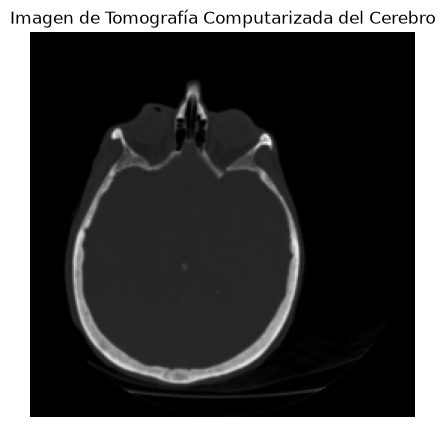

In [14]:
ct_img = ski.data.brain()  # Cargar la imagen de ejemplo del cerebro

# Extraer el slice central de la imagen 3D para visualizarlo en 2D
slice_index = ct_img.shape[0] // 2
ct_img = ct_img[slice_index, :, :]

# Visualizar la imagen del cerebro
plt.figure(figsize=(5,5))
plt.imshow(ct_img, cmap='gray')
plt.axis('off')
plt.title('Imagen de Tomografía Computarizada del Cerebro')



In [15]:
# Visualizar el tipo de datos de la imagen y los píxeles
print("El tipo de la imagen es: ", type(ct_img))
print("El tipo de valores de los píxeles es: ", ct_img.dtype)

# Visualizar los valores mínimos y máximos de la imagen
print("Valor mínimo de la imagen:", ct_img.min())
print("Valor máximo de la imagen:", ct_img.max())

# Calcular el rango dinámico de la imagen
dynamic_range = ct_img.max() - ct_img.min()
print("El rango dinámico de la imagen es:", dynamic_range)


El tipo de la imagen es:  <class 'numpy.ndarray'>
El tipo de valores de los píxeles es:  uint16
Valor mínimo de la imagen: 0
Valor máximo de la imagen: 47089
El rango dinámico de la imagen es: 47089


> **Pregunta:** Viendo el tipo de valor de los píxeles de la imagen *uint16*. ¿Cuánta diferencia hay entre el rango dinámico de la imagen y el rango dinámico máximo del tipo de dato?

In [16]:
# Calcular el contraste de la imagen entre los píxeles del fondo y los píxeles del cerebro
fondo = ct_img[ct_img < 10000]
cerebro = ct_img[ct_img >= 10000]

# Calcular el contraste relativo como la diferencia entre los valores promedio de los píxeles del cerebro y del fondo
contraste_relativo = (cerebro.mean() - fondo.mean()) / (fondo.mean() + 1e-6)  # Agregar una constante pequeña para evitar la división por cero
print("El contraste relativo entre el cerebro y el fondo es:", contraste_relativo)

El contraste relativo entre el cerebro y el fondo es: 8.896014794288881


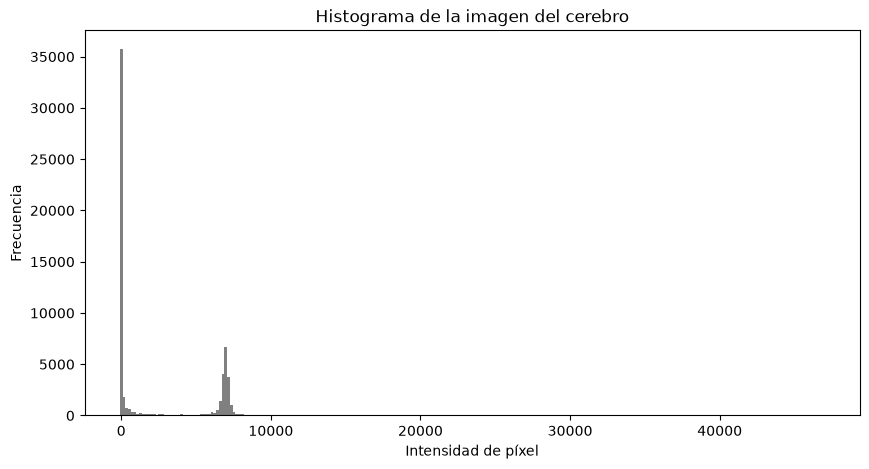

In [17]:
# Calcular el histograma de la imagen del cerebro
hist, bins = np.histogram(ct_img.flatten(), bins=256, range=(ct_img.min(), ct_img.max()))

# Visualizar el histograma
plt.figure(figsize=(10, 5))
plt.title("Histograma de la imagen del cerebro")
plt.bar(bins[:-1], hist, width=bins[1]-bins[0], color='gray')
plt.xlabel("Intensidad de píxel")
plt.ylabel("Frecuencia")
plt.show()

> **Pregunta:** ¿Qué información de las intensidades de la imagen podemos sacar del histograma? ¿Qué os llama la atención de los datos expuesto en el histograma?

Estos parámetros de calidad nos pueden ayudar a diferenciar entre la información útil presente en las imágenes y la parte de la información con información irrelevante. Esta parte de la imagen que no es parte de la señal original se conoce como **ruido** y degrada la imagen original. Se suele representar como una función de suma que añade degradación a la señal de la imagen. El resultado final de la imagen es:
$$g(x, y) = f(x, y) + n(x, y)$$

El ruido es un proceso aleatorio, pero se pueden clasificar dependiendo del tipo de función de $n(x, y)$.

### Ruido Gaussiano

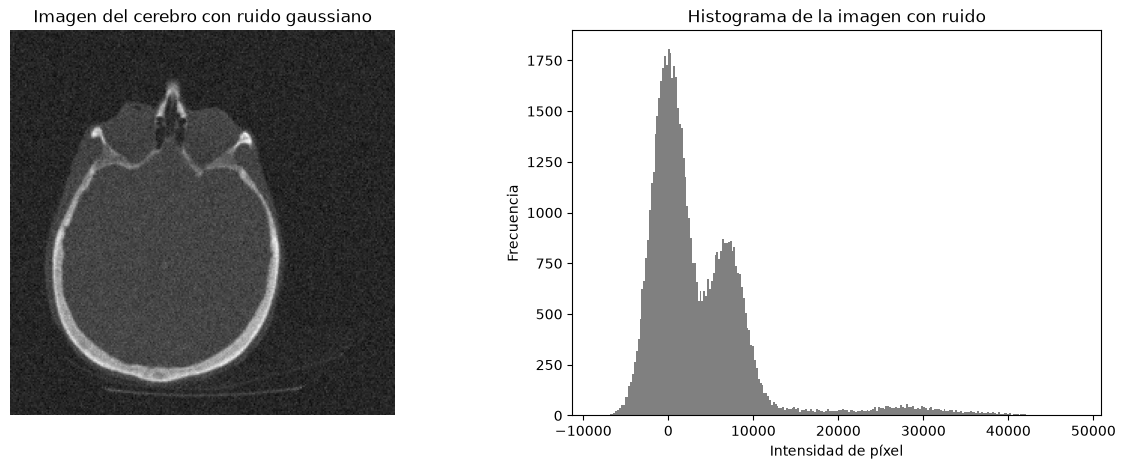

In [18]:
# Añadir ruido gaussiano a la imagen del cerebro

sigma = 2000  # Desviación estándar del ruido

ruido = np.random.normal(0, sigma, ct_img.shape)
ct_img_ruido = ct_img + ruido

# Visualizar la imagen con ruido y su histograma
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.imshow(ct_img_ruido, cmap='gray')
plt.title('Imagen del cerebro con ruido gaussiano')
plt.axis('off')
plt.subplot(1, 2, 2)
hist_ruido, bins_ruido = np.histogram(ct_img_ruido.flatten(), bins=256, range=(ct_img_ruido.min(), ct_img_ruido.max()))
plt.title("Histograma de la imagen con ruido")
plt.bar(bins_ruido[:-1], hist_ruido, width=bins_ruido[1]-bins_ruido[0], color='gray')
plt.xlabel("Intensidad de píxel")
plt.ylabel("Frecuencia")
plt.show()

### Ruido uniforme

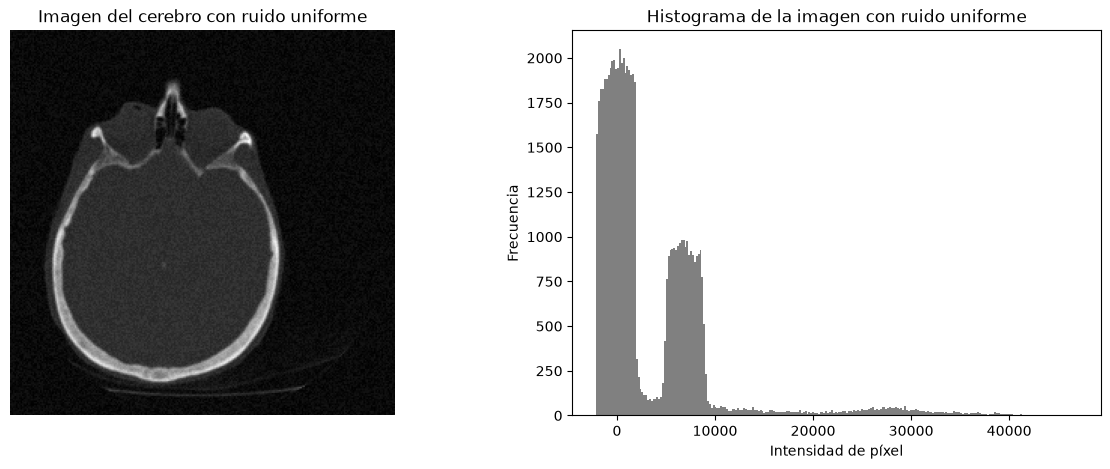

In [19]:
# Añadir ruido uniforme a la imagen del cerebro

low = -2000
high = 2000
ruido_uniforme = np.random.uniform(low, high, ct_img.shape)
ct_img_ruido_uniforme = ct_img + ruido_uniforme

# Visualizar la imagen con ruido uniforme y su histograma
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.imshow(ct_img_ruido_uniforme, cmap='gray')
plt.title('Imagen del cerebro con ruido uniforme')
plt.axis('off')
plt.subplot(1, 2, 2)
hist_ruido_uniforme, bins_ruido_uniforme = np.histogram(ct_img_ruido_uniforme.flatten(), bins=256, range=(ct_img_ruido_uniforme.min(), ct_img_ruido_uniforme.max()))
plt.title("Histograma de la imagen con ruido uniforme")
plt.bar(bins_ruido_uniforme[:-1], hist_ruido_uniforme, width=bins_ruido_uniforme[1]-bins_ruido_uniforme[0], color='gray')
plt.xlabel("Intensidad de píxel")
plt.ylabel("Frecuencia")
plt.show()

### Ruido sal y pimienta (impulsivo)


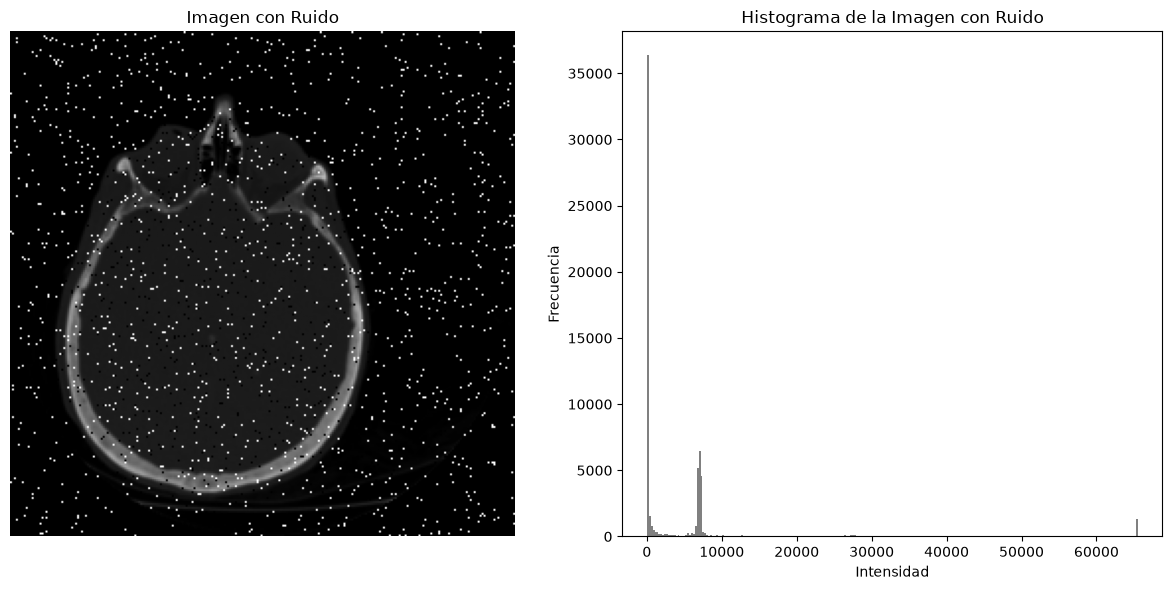

In [20]:
# Añadir ruido sal y pimienta a la imagen del cerebro
def agregar_ruido_sal_pimienta(imagen, probabilidad):
    imagen_ruidosa = imagen.copy()
    
    # Calcular el número exacto de píxeles a modificar
    num_pixeles = imagen.shape[0] * imagen.shape[1]
    num_ruido = int(probabilidad * num_pixeles)
    
    # Seleccionar solo los índices que cambiarán (sin procesar la imagen entera)
    indices = np.random.choice(num_pixeles, num_ruido * 2, replace=False)
    indices_sal = indices[:num_ruido]
    indices_pimienta = indices[num_ruido:]
    
    # Si la imagen tiene canales, aplanamos temporalmente la vista 2D/3D
    forma_original = imagen_ruidosa.shape
    vista_plana = imagen_ruidosa.reshape(-1, *forma_original[2:])
    
    vista_plana[indices_sal] = 65535
    vista_plana[indices_pimienta] = 0
    
    return imagen_ruidosa

# Aplicar la función de ruido a la imagen del cerebro
imagen_cerebro_ruidosa = agregar_ruido_sal_pimienta(ct_img, 0.02)

# Mostrar la imagen con ruido y su histograma
plt.figure(figsize=(12, 6))

# Mostrar la imagen con ruido
plt.subplot(1, 2, 1)
plt.imshow(imagen_cerebro_ruidosa, cmap='gray')
plt.title('Imagen con Ruido')
plt.axis('off')

# Mostrar el histograma
plt.subplot(1, 2, 2)
plt.hist(imagen_cerebro_ruidosa.ravel(), bins=256, range=(0, 65535), color='gray')
plt.title('Histograma de la Imagen con Ruido')
plt.xlabel('Intensidad')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Ruido periódico



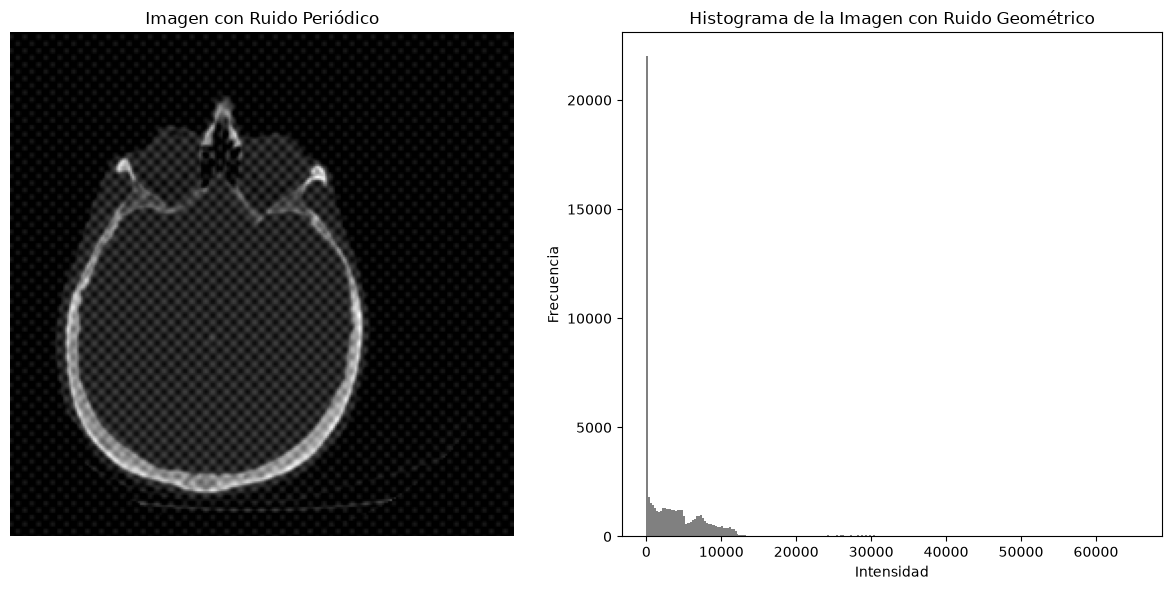

In [21]:
# Añadir ruido periódico a la imagen del cerebro

def agregar_ruido_periodico(imagen, frecuencia=0.4, amplitud=40.0, angulo=0):
    """
    Agrega ruido periódico (cuadrícula/patrón sinusoidal) como el de la imagen de resonancia.

    :param imagen: Array de NumPy con la imagen original.
    :param frecuencia: Frecuencia espacial de la onda (a mayor valor, más fina la malla).
    :param amplitud: Intensidad o visibilidad del ruido.
    :param angulo: Ángulo de inclinación del patrón en radianes.
    :return: Imagen con ruido periódico aplicado.
    """
    h, w = imagen.shape[:2]

    # 1. Crear coordenadas X e Y
    y, x = np.ogrid[:h, :w]

    # 2. Generar onda sinusoidal bidimensional (cuadrícula cruzada X e Y)
    # Sumar seno en X y seno en Y produce la red/malla de puntos
    sin_x = np.sin(2 * np.pi * frecuencia * (x * np.cos(angulo) + y * np.sin(angulo)))
    sin_y = np.sin(2 * np.pi * frecuencia * (-x * np.sin(angulo) + y * np.cos(angulo)))

    patron_malla = (sin_x + sin_y) / 2.0

    # 3. Sumar el patrón a la imagen original
    imagen_ruidosa = imagen.astype(np.float64) + amplitud * patron_malla

    # 4. Asegurar que los valores permanezcan en el rango válido del tipo de dato
    if np.issubdtype(imagen.dtype, np.integer):
        max_val = np.iinfo(imagen.dtype).max
        imagen_ruidosa = np.clip(imagen_ruidosa, 0, max_val)
        return imagen_ruidosa.astype(imagen.dtype)
    else:
        return np.clip(imagen_ruidosa, 0.0, 1.0)

imagen_cerebro_distorsionada = agregar_ruido_periodico(ct_img, frecuencia=0.2, amplitud=5000, angulo=np.pi/4)

# Mostrar la imagen con ruido periódico y su histograma
plt.figure(figsize=(12, 6))

# Mostrar la imagen con ruido
plt.subplot(1, 2, 1)
plt.imshow(imagen_cerebro_distorsionada, cmap='gray')
plt.title('Imagen con Ruido Periódico')
plt.axis('off')

# Mostrar el histograma
plt.subplot(1, 2, 2)
plt.hist(imagen_cerebro_distorsionada.ravel(), bins=256, range=(0, 65535), color='gray')
plt.title('Histograma de la Imagen con Ruido Geométrico')
plt.xlabel('Intensidad')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## Métricas de calidad de imagen

En tareas de comparación/recuperación de imágenes se usan métricas numéricas que cuantifican la diferencia entre una imagen de referencia f(x,y) y una imagen evaluada g(x,y). A continuación se describen las más comunes:

- RMSE (Root Mean Square Error)  
    $$\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}\big(f_i - g_i\big)^2}$$
    
    Unidad: misma que los píxeles. Interpretación: cuanto menor, mejor. Sensible a grandes errores puntuales (outliers).

- MSE (Mean Squared Error)  
    $$\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}\big(f_i - g_i\big)^2$$
    Se utiliza para cálculos intermedios (PSNR) y en funciones de pérdida.

- MAE (Mean Absolute Error)  
    $$\mathrm{MAE} = \frac{1}{N}\sum_{i=1}^{N}|f_i - g_i|$$
    Más robusta frente a outliers que la MSE/RMSE; interpreta la desviación media absoluta.

- PSNR (Peak Signal-to-Noise Ratio)  
    $$\mathrm{PSNR} = 10\log_{10}\!\left(\frac{MAX_I^2}{\mathrm{MSE}}\right)$$
    donde MAX_I es el valor máximo posible del pixel (por ejemplo 255 para uint8). Unidad: decibelios (dB). Interpretación: cuanto mayor, mejor; valores típicos para imágenes 8‑bit: 20–40 dB (más alto = más parecido).

- SNR (Signal-to-Noise Ratio)  
    $$\mathrm{SNR} = 10\log_{10}\!\left(\frac{\mathrm{Var}(\text{señal})}{\mathrm{Var}(\text{ruido})}\right)$$
    Mide la relación entre potencia de la señal y potencia del ruido. Mayor es mejor.

- SSIM (Structural Similarity Index)  
    SSIM evalúa similitud en luminancia, contraste y estructura en ventanas locales. Devuelve un valor en [-1,1] (habitualmente [0,1]) donde 1 indica identidad perceptual. Más alineado con la percepción humana que PSNR/MSE. Podemos utilizar la función [metrics.structural_similarity](https://scikit-image.org/docs/stable/api/skimage.metrics.html#skimage.metrics.structural_similarity) dentro del paquete de métricas de scikit-image.

Notas prácticas:
- Normaliza las imágenes o usa el mismo rango/bit‑depth antes de comparar (p. ej. dividir por MAX_I para float en [0,1]).
- PSNR y RMSE cuantifican diferencias matemáticas; SSIM suele reflejar mejor la calidad percibida.
- Elige la métrica según el objetivo: detección de artefactos globales (PSNR/MSE), robustez a outliers (MAE), o percepción visual (SSIM).

In [22]:
# Definir funciones para calcular métricas de calidad de imagen

# RMSE (Root Mean Square Error) entre la imagen original y la imagen con ruido
def calcular_rmse(imagen_original, imagen_ruidosa):
    """
    Calcula el error cuadrático medio (RMSE) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del RMSE.
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular RMSE.")

    # Calcular el RMSE
    rmse = np.sqrt(np.mean((imagen_original.astype(np.float64) - imagen_ruidosa.astype(np.float64)) ** 2))
    return rmse


# MSE (Mean Squared Error) entre la imagen original y la imagen con ruido
def calcular_mse(imagen_original, imagen_ruidosa):
    """
    Calcula el error cuadrático medio (MSE) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del MSE.
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular MSE.")

    # Calcular el MSE
    mse = np.mean((imagen_original.astype(np.float64) - imagen_ruidosa.astype(np.float64)) ** 2)
    return mse


# MAE (Mean Absolute Error) entre la imagen original y la imagen con ruido
def calcular_mae(imagen_original, imagen_ruidosa):
    """
    Calcula el error absoluto medio (MAE) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del MAE.
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular MAE.")

    # Calcular el MAE
    mae = np.mean(np.abs(imagen_original.astype(np.float64) - imagen_ruidosa.astype(np.float64)))
    return mae


# pSNR (Peak Signal-to-Noise Ratio) entre la imagen original y la imagen con ruido
def calcular_psnr(imagen_original, imagen_ruidosa):
    """
    Calcula la relación señal-ruido de pico (pSNR) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del pSNR en decibelios (dB).
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular pSNR.")

    # Calcular el MSE
    mse = calcular_mse(imagen_original, imagen_ruidosa)

    # Evitar división por cero
    if mse == 0:
        return float('inf')

    # Calcular el valor máximo posible del pixel (dependiendo del tipo de dato)
    max_pixel_value = np.iinfo(imagen_original.dtype).max if np.issubdtype(imagen_original.dtype, np.integer) else 1.0

    # Calcular pSNR
    psnr = 20 * np.log10(max_pixel_value / np.sqrt(mse))
    return psnr


# SNR (Signal-to-Noise Ratio) entre la imagen original y la imagen con ruido
def calcular_snr(imagen_original, imagen_ruidosa):
    """
    Calcula la relación señal-ruido (SNR) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del SNR en decibelios (dB).
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular SNR.")

    # Calcular la potencia de la señal y del ruido
    potencia_senal = np.mean(imagen_original.astype(np.float64) ** 2)
    potencia_ruido = np.mean((imagen_original.astype(np.float64) - imagen_ruidosa.astype(np.float64)) ** 2)

    # Evitar división por cero
    if potencia_ruido == 0:
        return float('inf')

    # Calcular SNR
    snr = 10 * np.log10(potencia_senal / potencia_ruido)
    return snr


# Structural Similarity Index (SSIM) entre la imagen original y la imagen con ruido
from skimage.metrics import structural_similarity as ssim

def calcular_ssim(imagen_original, imagen_ruidosa):
    """
    Calcula el índice de similitud estructural (SSIM) entre la imagen original y la imagen con ruido.

    :param imagen_original: Array de NumPy con la imagen original.
    :param imagen_ruidosa: Array de NumPy con la imagen con ruido.
    :return: Valor del SSIM.
    """
    # Asegurarse de que ambas imágenes tengan el mismo tamaño
    if imagen_original.shape != imagen_ruidosa.shape:
        raise ValueError("Las imágenes deben tener el mismo tamaño para calcular SSIM.")

    # Calcular SSIM
    ssim_value = ssim(imagen_original.astype(np.float64), imagen_ruidosa.astype(np.float64), multichannel=True, data_range=imagen_original.max() - imagen_original.min())
    return ssim_value

In [24]:
# Calcular y mostrar las métricas de calidad de imagen para la imagen con ruido gaussiano
rmse_gaussiano = calcular_rmse(ct_img, ct_img_ruido)
mse_gaussiano = calcular_mse(ct_img, ct_img_ruido)
mae_gaussiano = calcular_mae(ct_img, ct_img_ruido)
psnr_gaussiano = calcular_psnr(ct_img, ct_img_ruido)
snr_gaussiano = calcular_snr(ct_img, ct_img_ruido)
ssim_gaussiano = calcular_ssim(ct_img, ct_img_ruido)

# Calcular y mostrar las métricas de calidad de imagen para la imagen con ruido uniforme
rmse_uniforme = calcular_rmse(ct_img, ct_img_ruido_uniforme)
mse_uniforme = calcular_mse(ct_img, ct_img_ruido_uniforme)
mae_uniforme = calcular_mae(ct_img, ct_img_ruido_uniforme)
psnr_uniforme = calcular_psnr(ct_img, ct_img_ruido_uniforme)
snr_uniforme = calcular_snr(ct_img, ct_img_ruido_uniforme)
ssim_uniforme = calcular_ssim(ct_img, ct_img_ruido_uniforme)

# Calcular y mostrar las métricas de calidad de imagen para la imagen con ruido sal y pimienta
rmse_sal_pimienta = calcular_rmse(ct_img, imagen_cerebro_ruidosa)
mse_sal_pimienta = calcular_mse(ct_img, imagen_cerebro_ruidosa)
mae_sal_pimienta = calcular_mae(ct_img, imagen_cerebro_ruidosa)
psnr_sal_pimienta = calcular_psnr(ct_img, imagen_cerebro_ruidosa)
snr_sal_pimienta = calcular_snr(ct_img, imagen_cerebro_ruidosa)
ssim_sal_pimienta = calcular_ssim(ct_img, imagen_cerebro_ruidosa)

# Calcular y mostrar las métricas de calidad de imagen para la imagen con ruido periódico
rmse_periodico = calcular_rmse(ct_img, imagen_cerebro_distorsionada)
mse_periodico = calcular_mse(ct_img, imagen_cerebro_distorsionada)
mae_periodico = calcular_mae(ct_img, imagen_cerebro_distorsionada)
psnr_periodico = calcular_psnr(ct_img, imagen_cerebro_distorsionada)
snr_periodico = calcular_snr(ct_img, imagen_cerebro_distorsionada)
ssim_periodico = calcular_ssim(ct_img, imagen_cerebro_distorsionada)

# Mostrar los resultados de las métricas de calidad de imagen en un formato tabular
import pandas as pd
pd.set_option('display.float_format', '{:.4f}'.format)  # Formatear los números a 4 decimales
# Crear un DataFrame para mostrar los resultados de las métricas de calidad de imagen
resultados = pd.DataFrame({
    'Métrica': ['RMSE', 'MSE', 'MAE', 'pSNR (dB)', 'SNR (dB)', 'SSIM'],
    'Ruido Gaussiano': [rmse_gaussiano, mse_gaussiano, mae_gaussiano, psnr_gaussiano, snr_gaussiano, ssim_gaussiano],
    'Ruido Uniforme': [rmse_uniforme, mse_uniforme, mae_uniforme, psnr_uniforme, snr_uniforme, ssim_uniforme],
    'Ruido Sal y Pimienta': [rmse_sal_pimienta, mse_sal_pimienta, mae_sal_pimienta, psnr_sal_pimienta, snr_sal_pimienta, ssim_sal_pimienta],
    'Ruido Periódico': [rmse_periodico, mse_periodico, mae_periodico, psnr_periodico, snr_periodico, ssim_periodico]
})  

# Mostrar el DataFrame con los resultados
print(resultados)

     Métrica  Ruido Gaussiano  Ruido Uniforme  Ruido Sal y Pimienta  \
0       RMSE        1997.0503       1151.7286             8829.5766   
1        MSE     3988210.0475    1326478.7995         77961423.0379   
2        MAE        1596.0640        996.1918             1303.4863   
3  pSNR (dB)          30.3217         35.1025               17.4107   
4   SNR (dB)          11.2904         16.0712               -1.6206   
5       SSIM           0.4088          0.6434                0.3929   

   Ruido Periódico  
0        2079.2643  
1     4323340.1184  
2        1421.6106  
3          29.9713  
4          10.9400  
5           0.2859  


> **Pregunta:** Viendo las métricas presentadas en la tabla anterior, ¿qué ruido es el que menos afecta a la calidad de la imagen?